In [1]:
import pandas as pd
df_large_nj = pd.read_csv('solve_results/solve_log_generated_progressive_large_nj.csv', header=None)
df_large_nj.columns = ['data_name', 'total_robots', 'solve_time_vrp', 'obj_value_vrp', 'processed_nodes_vrp', 'gap_vrp', 'solve_time_flow', 'obj_value_flow', 'processed_nodes_flow', 'gap_flow','avg_num_robots', 'date']


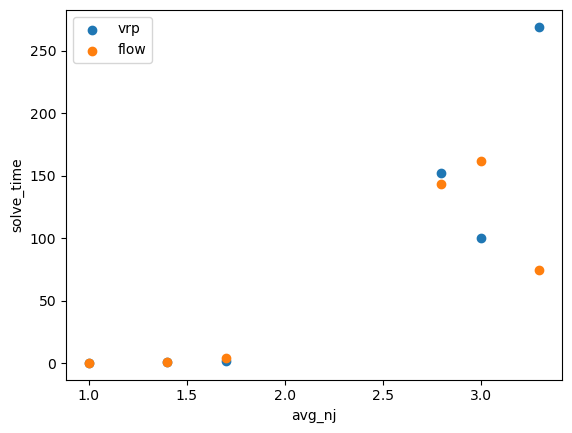

In [33]:
#scatter plot data, y column corresponding to solve_time, x column corresponding to avg_num_robots for vrp and flow and 
import matplotlib.pyplot as plt
plt.figure()
df_large_nj_small = df_large_nj[df_large_nj['solve_time_vrp'] < 890]
df_large_nj_small = df_large_nj_small[df_large_nj_small['data_name'] == 'generated5_large.csv']
plt.scatter(df_large_nj_small['avg_num_robots'], df_large_nj_small['solve_time_vrp'], label='vrp')
plt.scatter(df_large_nj_small['avg_num_robots'], df_large_nj_small['solve_time_flow'], label='flow')
plt.xlabel('avg_nj')
plt.ylabel('solve_time')
plt.legend()
plt.show()


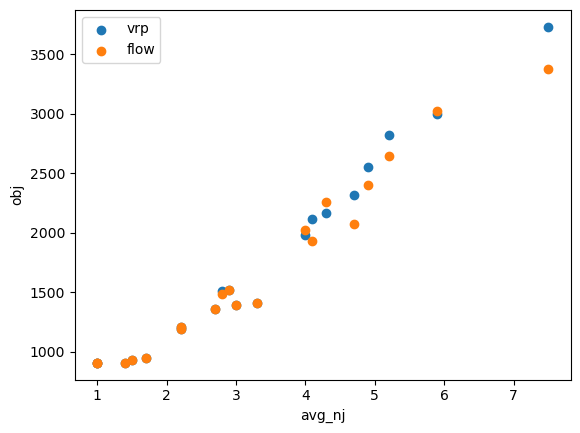

In [44]:
plt.figure()
df_large_nj_small = df_large_nj
df_large_nj_small = df_large_nj_small[df_large_nj_small['data_name'] == 'generated16_large.csv']
plt.scatter(df_large_nj_small['avg_num_robots'], df_large_nj_small['obj_value_vrp'], label='vrp')
plt.scatter(df_large_nj_small['avg_num_robots'], df_large_nj_small['obj_value_flow'], label='flow')
plt.xlabel('avg_nj')
plt.ylabel('obj')
plt.legend()
plt.show()


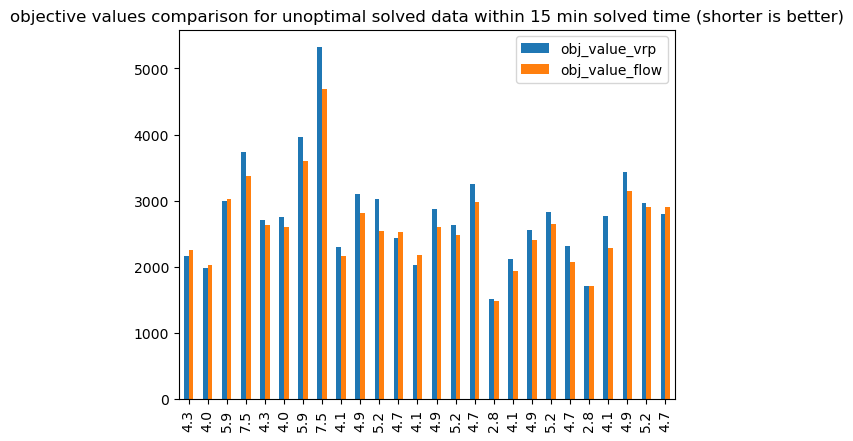

In [24]:
df_large_nj_plus_850 = df_large_nj[df_large_nj['solve_time_vrp'] > 850]
df_large_nj_plus_850[['obj_value_vrp', 'obj_value_flow']].plot(kind='bar')
plt.xticks(range(df_large_nj_plus_850.shape[0]), df_large_nj_plus_850['avg_num_robots'])
plt.title('objective values comparison for unoptimal solved data within 15 min solved time (shorter is better)')
plt.show()

In [ ]:
# bar plor data of two columns obj_value_vrp and obj_value_flow for each data that has solve_time_vrp more than 850, the x column is the avg_num_robots
df_large_nj_plus_850[['obj_value_vrp', 'obj_value_flow']].plot(kind='bar')

## Compare VRP and flow base model

In [7]:
#Read data from file flow_based.csv and save it as a dataframe. Here are the columns of the data.
# ,data,obj_value,solve_time,processed_nodes,gap,robots,tasks
# 0,generated0,2142.68,0.09,385,0.0,1,5
# 1,generated1,1668.03,0.08,391,0.0,1,5

df_flow_based = pd.read_csv('solve_results/flow_based.csv')

#Read data from file vrp_based.csv and save it as a dataframe
df_vrp_based = pd.read_csv('solve_results/vrp_based.csv')

In [ ]:
uninserted = tasks
while len(uninserted) > 0:
    initialize inserted_paths and cost dictionary L
    for task in uninserted:
        for path in paths:
            calculate cost_if_insert of task into path and store in L
    sort L by increasing cost_if_insert
    remaining robots = total robots
    determine number of tasks to insert k
    for each (task, path, cost_if_insert) in sorted(L):
        if task cannot be assigned: # task.nj > remaining robots
            continue
        num_inserted[task] += 1
        best_paths[task].append(path)
        cur_task[path].append(task)
        if num_inserted[task] == task.nj: # task is fully assigned
            uninserted.remove(task)
            for path in best_paths[task]:
                path.append(task)
                for task_prime in cur_task[path]:
                    best_paths[task_prime_idx].remove(path)
                    num_inserted[task_prime_idx] = num_inserted[task_prime_idx] - 1
            k = k - 1
            if k == 0:
                break



In [9]:
df_flow_based

,Unnamed: 0,data,obj_value,solve_time,processed_nodes,gap,robots,tasks
0,0,generated0,2142.68,0.09,385,0.00,1,5
1,1,generated1,1668.03,0.08,391,0.00,1,5
2,2,generated2,2007.92,0.08,384,0.00,1,5
3,3,generated3,2405.53,0.08,415,0.00,1,5
4,4,generated4,3990.35,548.44,6066060,0.00,1,10
5,5,generated5,3796.26,515.67,6094330,0.00,1,10
6,6,generated6,4055.75,566.94,6439148,0.00,1,10
7,7,generated7,4511.00,544.81,6635266,0.00,1,10
8,8,generated8,6454.95,7200.08,23263025,0.93,1,15
9,9,generated9,5278.26,7201.74,22337311,0.93,1,15


In [15]:
#Merge the two dataframes on the column 'data' and save the result as a new dataframe, keep the folliwng columns: obj_value, solve_time, robots, tasks,gap
df_merged = pd.merge(df_flow_based, df_vrp_based, on='data', suffixes=('_flow', '_vrp'))[['obj_value_flow', 'solve_time_flow', 'robots_flow', 'tasks_flow', 'gap_flow', 'obj_value_vrp', 'solve_time_vrp', 'robots_vrp', 'tasks_vrp', 'gap_vrp']]
# we don't need 4 columns for robots and tasks, we can keep $robots_flow$ and $tasks_flow$ only
df_merged = df_merged[['obj_value_flow', 'solve_time_flow', 'robots_flow', 'tasks_flow', 'gap_flow', 'obj_value_vrp', 'solve_time_vrp', 'gap_vrp']]
#Change column name $robots_flow$ to $robots$ and $tasks_flow$ to $tasks$
df_merged = df_merged.rename(columns={'robots_flow': 'robots', 'tasks_flow': 'tasks'})

In [17]:
#Create a new column $improvement$ which is calculated as (obj_value_vrp- obj_value_flow)/obj_value_vrp
df_merged['improvement'] = (df_merged['obj_value_vrp'] - df_merged['obj_value_flow'])/df_merged['obj_value_vrp']

In [19]:
#Group the data by the column $robots$ and $tasks$ and calculate the mean of the column $improvement$ for each group, 
df_grouped = df_merged.groupby(['robots', 'tasks']).mean().reset_index()

In [22]:
#save df_grouped to a csv file
df_grouped.to_csv('df_grouped_compare_csv_vrp.csv', index=False)

# Draw tabu over iterations line

In [2]:
import pandas as pd
from matplotlib import pyplot as plt

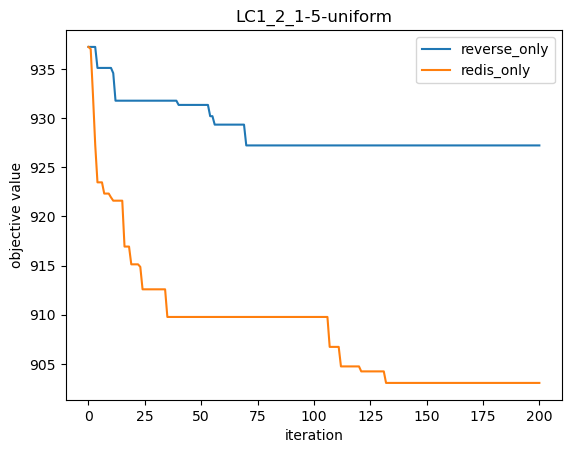

In [14]:
# In .\solve_results\tabu\best_fitnesses there is a file called LC1_2_1-5-uniform_2024-09-19_10-59-54reverse_only_best_fitnesses0.txt
# In this file, the data are im the following format:
#RANDOM_SEED: 16
# NUM_REVERSE_NEIGHBORS: 10
# NUM_REROUTE_NEIGHBORS: 0
# NUM_REDISTRIBUTE_NEIGHBORS: 0
# MAX_TL_ADD_SIZE: 13
# MAX_TL_DROP_SIZE: 13
# MAX_TL_REDISTRIBUTE_SIZE: 10
# MAX_ITER: 200
# FIND_FROM_ELITE_AFTER: 200
# RESTART_AFTER: 400
# REROUTE_ON_CRITICAL: True
# REVERSE_ON_CRITICAL: True
# REVERSE_CRITICAL_LONGEST_EDGE: True
# cfg.TABU_REDISTRIBUTE_PROB: 0.3
# SOLVE_RESULT
# 937.2506795011043
# 937.2506795011043
# 937.2506795011043
# 937.2506795011043
# 935.1138551785186
# 935.1138551785186
# 935.1138551785186
#...
#in which we want to retrieve data after the line SOLVE_RESULT and plot it as a line plot
# there are also a file called LC1_2_1-5-uniform_2024-09-18redis_only_best_fitnesses0.txt in the same directory
# the data format is the same as the previous file, read the file and plot the data on the same plot as the previous one
# use different color for the two lines

with open('solve_results/tabu/best_fitnesses/LC1_2_1-5-uniform_2024-09-19_10-59-54reverse_only_best_fitnesses0.txt') as f:
    lines = f.readlines()
    data = [float(line.strip()) for line in lines[15:]]
    plt.plot(data, label='reverse_only')

# read the second file and plot the data on the SAME plot
with open('solve_results/tabu/best_fitnesses/LC1_2_1-5-uniform_2024-09-18redis_only_best_fitnesses0.txt') as f:
    lines = f.readlines()
    data = [float(line.strip()) for line in lines[15:]]
    plt.plot(data, label='redis_only')
    plt.legend()

plt.title('LC1_2_1-5-uniform')
# x-axis is the iteration number
# y-axis is the objective value
plt.xlabel('iteration')
plt.ylabel('objective value')
plt.show()

In [17]:
first_names = ['LC1']
sec_names = [2,4]
third_names = [i for i in range(1,11)]
data_names = [f'{i}_{j}_{k}-5-uniform' for i in first_names for j in sec_names for k in third_names]
data_paths_redis =[f'solve_results/tabu/best_fitnesses/{data_name}_2024-09-18redis_only_best_fitnesses0.txt'for data_name in data_names]#
data_paths_reverse =[f'solve_results/tabu/best_fitnesses/{data_name}_2024-09-19reverse_only_best_fitnesses0.txt'for data_name in data_names]#
num_robots = [10*i for i in range(1,4)]
method = 5
file_type = 'csv'
is_depot_task = False

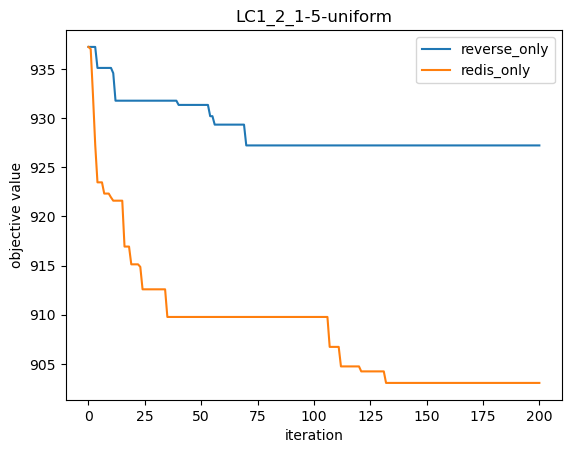

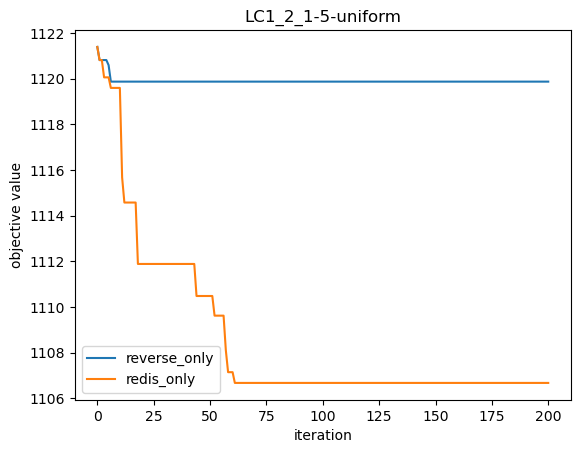

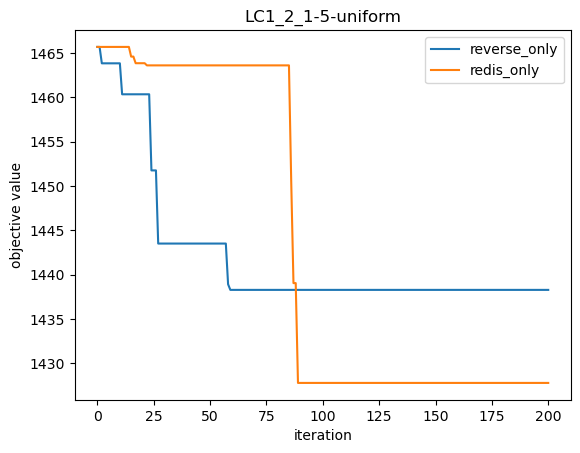

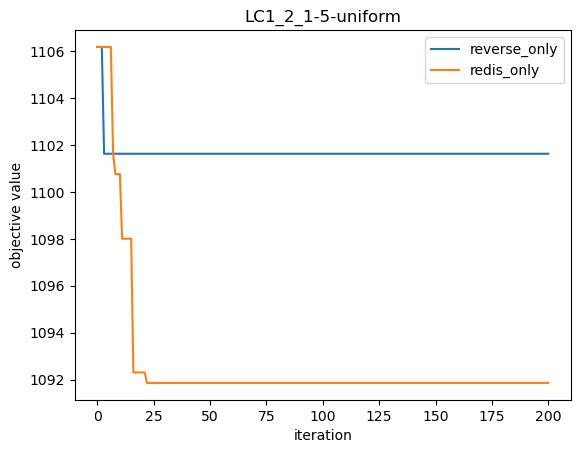

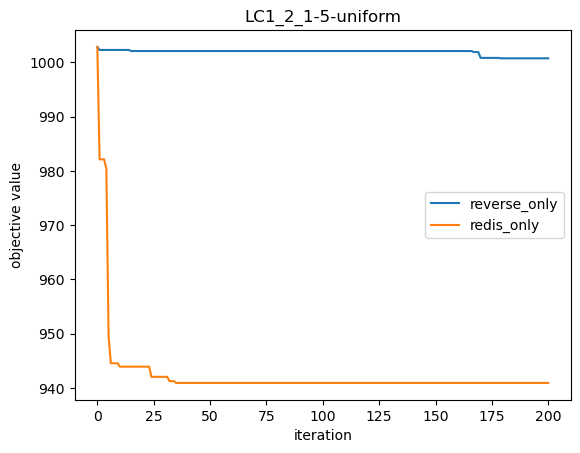

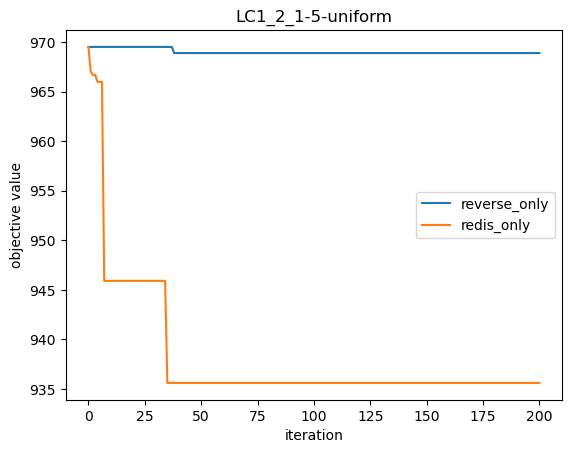

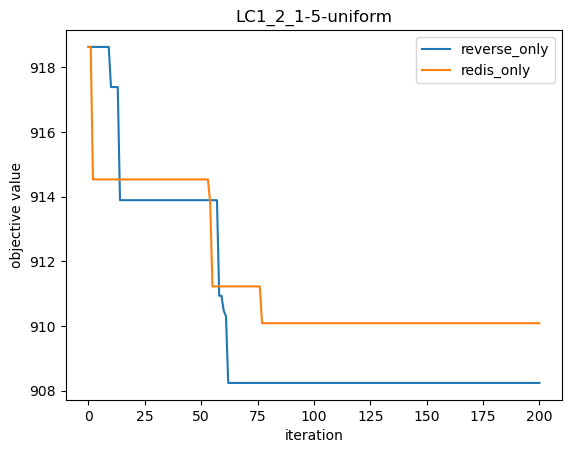

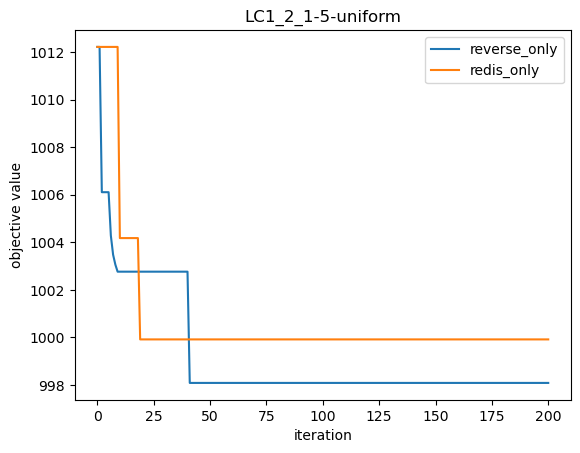

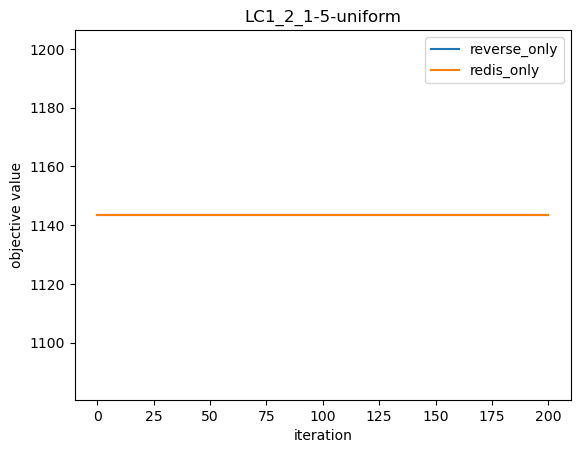

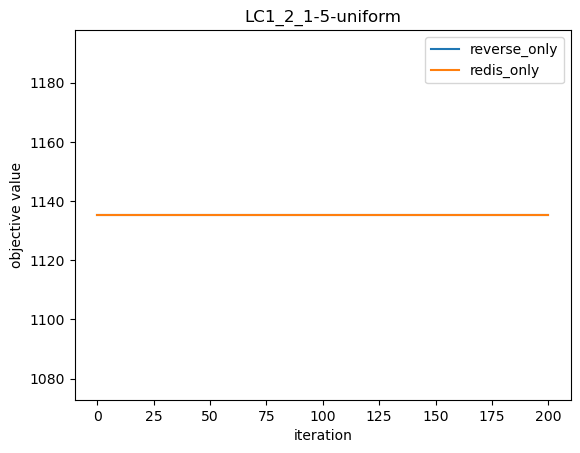

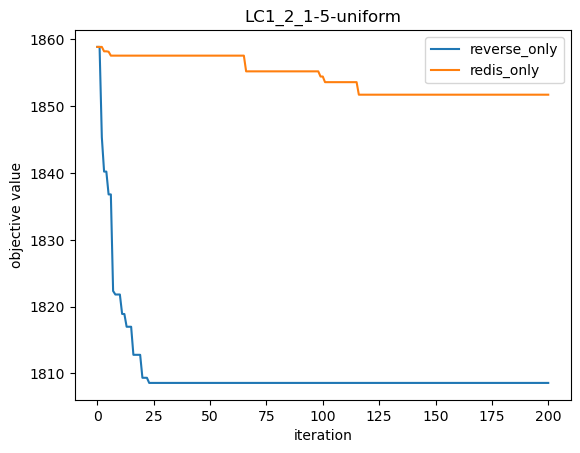

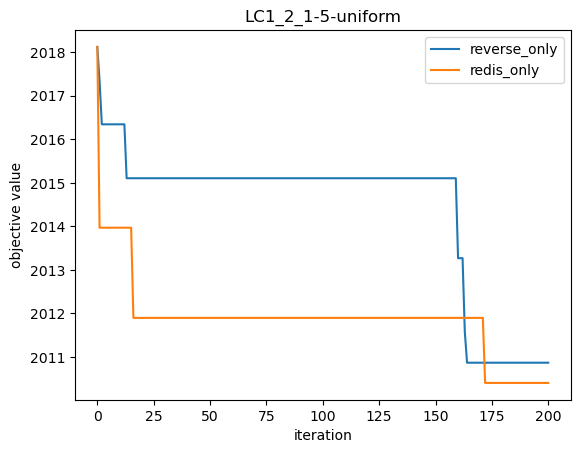

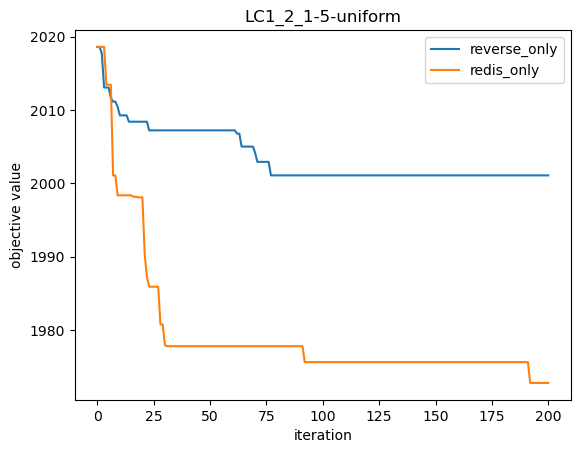

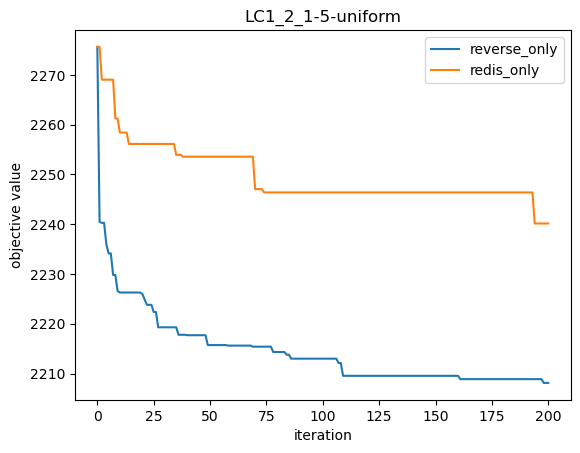

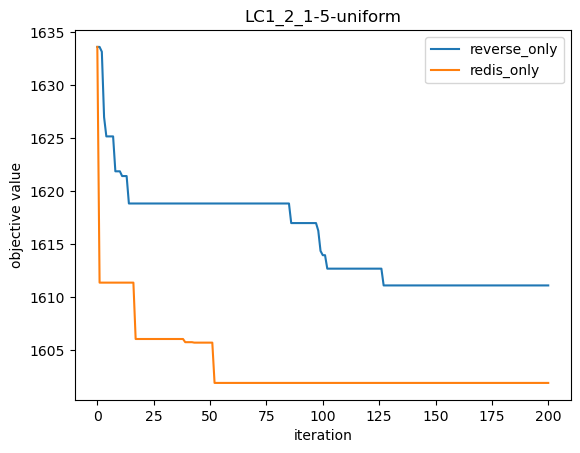

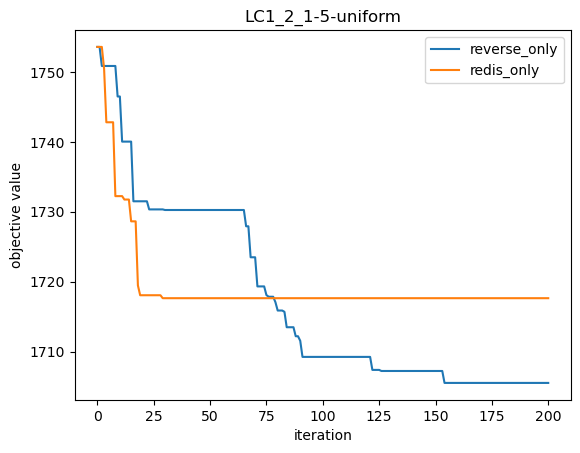

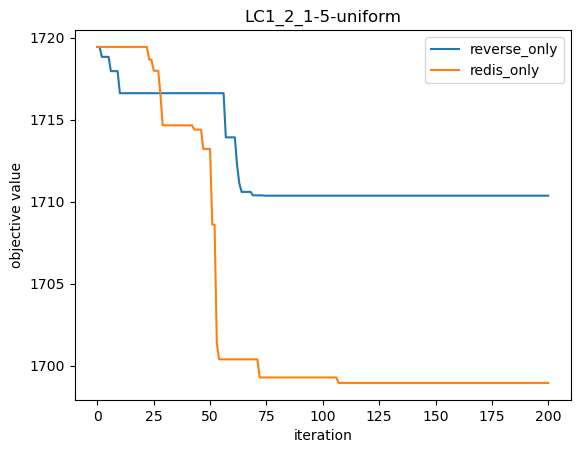

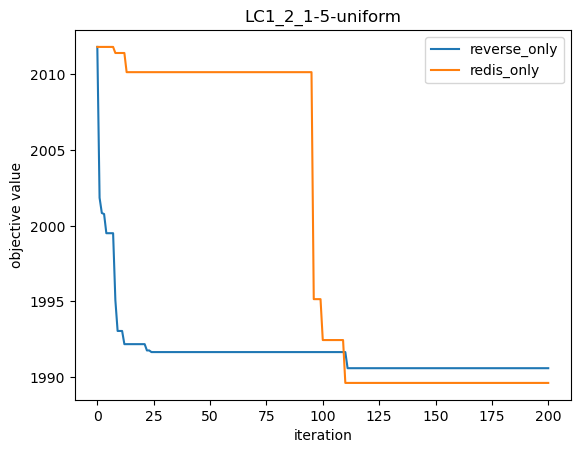

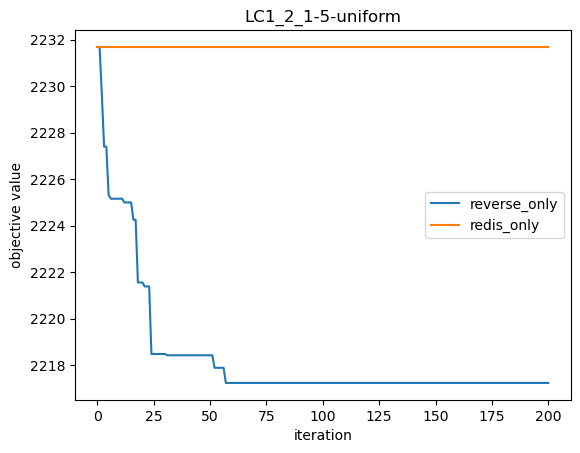

FileNotFoundError: [Errno 2] No such file or directory: 'solve_results/tabu/best_fitnesses/LC1_4_10-5-uniform_2024-09-18redis_only_best_fitnesses0.txt'

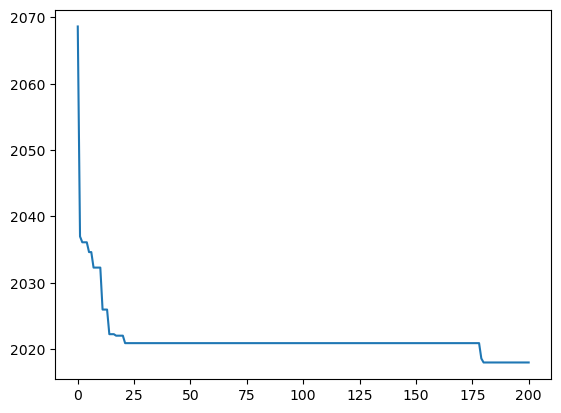

In [25]:
for data_name, path_redis,path_reverse in zip(data_names, data_paths_redis, data_paths_reverse):
    with open(path_reverse) as f:
        lines = f.readlines()
        data = [float(line.strip()) for line in lines[15:]]
        plt.plot(data, label='reverse_only')

    # read the second file and plot the data on the SAME plot
    with open(path_redis) as f:
        lines = f.readlines()
        data = [float(line.strip()) for line in lines[15:]]
        plt.plot(data, label='redis_only')
        
    plt.legend()
    plt.title('LC1_2_1-5-uniform')
    # x-axis is the iteration number
    # y-axis is the objective value
    plt.xlabel('iteration')
    plt.ylabel('objective value')
    # plt.show()
    plt.savefig(f'solve_results/tabu/compare/{data_name}.png')

In [16]:
data_paths

['lim/200/LC1_2_1-5-uniform.csv',
 'lim/200/LC1_2_2-5-uniform.csv',
 'lim/200/LC1_2_3-5-uniform.csv',
 'lim/200/LC1_2_4-5-uniform.csv',
 'lim/200/LC1_2_5-5-uniform.csv',
 'lim/200/LC1_2_6-5-uniform.csv',
 'lim/200/LC1_2_7-5-uniform.csv',
 'lim/200/LC1_2_8-5-uniform.csv',
 'lim/200/LC1_2_9-5-uniform.csv',
 'lim/200/LC1_2_10-5-uniform.csv',
 'lim/400/LC1_4_1-5-uniform.csv',
 'lim/400/LC1_4_2-5-uniform.csv',
 'lim/400/LC1_4_3-5-uniform.csv',
 'lim/400/LC1_4_4-5-uniform.csv',
 'lim/400/LC1_4_5-5-uniform.csv',
 'lim/400/LC1_4_6-5-uniform.csv',
 'lim/400/LC1_4_7-5-uniform.csv',
 'lim/400/LC1_4_8-5-uniform.csv',
 'lim/400/LC1_4_9-5-uniform.csv',
 'lim/400/LC1_4_10-5-uniform.csv']

In [ ]:
file_path = 'solve_results\\tabu\\best_fitnesses\\LC1_2_1-5-uniform_2024-09-19_10-59-54reverse_only_best_fitnesses0.txt'
with open(file_path, 'r') as f:
    data = f.readlines()
    data = data[data.index('SOLVE_RESULT\n')+1:]
    data = [float(d) for d in data]
    plt.plot(data)
    plt.show()